# Spatial Accessibility with Pysal Access

**Authors:** Alexander Michels

In this notebook, we use the Pysall `access` package to calculate spatial accessibility to hospital beds using multiple methods.

In [1]:
import access
import contextily as cx
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm
import sys

In [2]:
pop_id = "FIPS"
figsize=(16, 14)

In [3]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop[pop_id] = pop[pop_id].astype(str)
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [4]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos), sum(hos["BEDS"]))
hos.head()

66 18259


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.89140)


In [5]:
access.Datasets.available_datasets()


chi_times: Cost matrix with travel times from each Chicago Census Tract to all others.

chi_doc: Doctor and dentist counts for each Chicago Census Tract.

chi_pop: Population counts for each Chicago Census Tract.

chi_doc_geom: Doctor and dentist counts for each Chicago Census Tract along with geometric representations for Census Tracts.

chi_pop_geom: Population counts for each Chicago Census Tract along with geometric representations for Census Tracts.

chi_euclidean: Euclidean distance cost matrix with distances from each demand Chicago Census Tract to all others.

chi_euclidean_neighbors: Euclidean distance cost matrix with distances from each supply Census Tract to all others.

cook_county_hospitals: Contains data for each hospital location in Cook County including X Y coordinates.

cook_county_hospitals_geom: Contains data for each hospital location in Cook County including X Y coordinates, and geometric points for each hospital.

cook_county_tracts: Geometric representation of 

In [6]:
cook_ct = access.Datasets.load_data("cook_county_tracts")
cook_ct["geoid"] = cook_ct["geoid"].astype(str)
cook_ct = cook_ct.to_crs("EPSG:4326")
cook_ct.head()

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geoid,geometry
0,1400000US17031440300,17,031,440300,4403,Tract,0.499,17031440300,"POLYGON ((-87.61467 41.74198, -87.61462 41.740..."
1,1400000US17031440600,17,031,440600,4406,Tract,0.259,17031440600,"POLYGON ((-87.61453 41.73650, -87.61450 41.735..."
2,1400000US17031440700,17,031,440700,4407,Tract,0.126,17031440700,"POLYGON ((-87.60967 41.73658, -87.60725 41.736..."
3,1400000US17031460200,17,031,460200,4602,Tract,0.232,17031460200,"POLYGON ((-87.55276 41.74464, -87.55150 41.744..."
4,1400000US17031460600,17,031,460600,4606,Tract,0.101,17031460600,"POLYGON ((-87.55629 41.73732, -87.55558 41.737..."


In [7]:
hospitals = gpd.sjoin(cook_ct[["geoid", "geometry"]], hos[["BEDS", "geometry"]], how="inner", predicate="intersects")
hospitals = hospitals.groupby("geoid").agg({"BEDS": 'sum', 'geoid': 'last', "geometry": 'last'})
print(len(hospitals), sum(hospitals["BEDS"]))
hospitals.head()

59 18259


,BEDS,geoid,geometry
geoid,,,
17031031000,189,17031031000,"POLYGON ((-87.66944 41.96888, -87.67102 41.968..."
17031031300,115,17031031300,"POLYGON ((-87.65215 41.97644, -87.64844 41.977..."
17031031400,184,17031031400,"POLYGON ((-87.64257 41.96245, -87.64225 41.961..."
17031032100,134,17031032100,"POLYGON ((-87.65634 41.96176, -87.65514 41.961..."
17031040300,279,17031040300,"POLYGON ((-87.70530 41.97764, -87.70576 41.979..."


In [8]:
hospitals["geoid"].is_unique

True

In [9]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car.head()

,origin,destination,minutes
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [10]:
# calculate the gravity-based access
A = access.Access(
    demand_df=pop,
    demand_index=pop_id,
    demand_value="E_TOTPOP",
    supply_df=hospitals,
    supply_index="geoid",
    supply_value="BEDS",
    cost_df=car,
    cost_origin="origin",
    cost_dest="destination",
    cost_name="minutes",
    neighbor_cost_df=car,
    neighbor_cost_origin="origin",
    neighbor_cost_dest="destination",
    neighbor_cost_name="minutes"
)

In [11]:
gravity = access.weights.gravity(scale=60, alpha=-1, min_dist=1)
e2sfca_weights_30 = access.weights.step_fn({10 : 1, 20 : 0.68, 30 : 0.22})
e2sfca_weights_60 = access.weights.step_fn({20 : 1, 40 : 0.68, 60 : 0.22})
gaussian10 = access.weights.gaussian(10)
gaussian20 = access.weights.gaussian(20)

In [12]:
A.weighted_catchment(name="gravity", weight_fn=gravity)

,gravity_BEDS
FIPS,
17031010100,28947.351633
17031010201,30688.468786
17031010202,29613.408700
17031010300,29395.681764
17031010400,31556.255500
...,...
17031843700,43879.409497
17031843800,38408.981742
17031843900,40165.980043


In [13]:
A.two_stage_fca(name="2sfca_30", max_cost=30)
A.two_stage_fca(name="2sfca_60", max_cost=60)

,2sfca_60_BEDS
FIPS,
17031010100,0.002790
17031010201,0.003022
17031010202,0.002956
17031010300,0.002931
17031010400,0.003050
...,...
17031843700,0.003858
17031843800,0.003801
17031843900,0.003801


In [14]:
A.enhanced_two_stage_fca(name="e2sfca_30", weight_fn=e2sfca_weights_30, max_cost=30)
A.enhanced_two_stage_fca(name="e2sfca_60", weight_fn=e2sfca_weights_60, max_cost=60)

,e2sfca_60_BEDS
FIPS,
17031010100,0.002484
17031010201,0.002714
17031010202,0.002645
17031010300,0.002648
17031010400,0.003023
...,...
17031843700,0.004963
17031843800,0.004360
17031843900,0.004146


In [15]:
A.enhanced_two_stage_fca(name="g2sfca10", weight_fn=gaussian10)
A.enhanced_two_stage_fca(name="g2sfca20", weight_fn=gaussian20)

,g2sfca20_BEDS
FIPS,
17031010100,0.002699
17031010201,0.002867
17031010202,0.002820
17031010300,0.002814
17031010400,0.003120
...,...
17031843700,0.005420
17031843800,0.004511
17031843900,0.004258


In [16]:
A.three_stage_fca(name="3sfca")

,3sfca_BEDS
FIPS,
17031010100,0.005337
17031010201,0.005148
17031010202,0.005539
17031010300,0.005940
17031010400,0.004095
...,...
17031843700,0.004093
17031843800,0.002721
17031843900,0.004008


In [17]:
A.raam(name="raam30", tau=30)
A.raam(name="raam60", tau=60)

,raam60_BEDS
FIPS,
17031010100,1.151754
17031010201,1.115558
17031010202,1.173011
17031010300,1.187285
17031010400,1.126623
...,...
17031843700,1.139529
17031843800,1.194155
17031843900,1.184715


In [18]:
print(len(A.access_df))
A.access_df.head()

1318


,E_TOTPOP,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
FIPS,,,,,,,,,,,
17031010100,4522,28947.351633,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754
17031010201,7039,30688.468786,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558
17031010202,2852,29613.408700,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011
17031010300,6650,29395.681764,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285
17031010400,5153,31556.255500,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623


In [19]:
access_result = A.access_df.merge(cook_ct[["geoid", "geometry"]], left_index=True, right_on="geoid").set_index("geoid")
access_result = gpd.GeoDataFrame(access_result)
access_result = access_result.drop(columns=["E_TOTPOP"])
print(len(access_result))
print(type(access_result))
access_result.head()

1318
<class 'geopandas.geodataframe.GeoDataFrame'>


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,28947.351633,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,30688.468786,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,29613.408700,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,29395.681764,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,31556.255500,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


In [20]:
supply_field = "BEDS"
result_cols = [
    "gravity",
    "2sfca_30", "2sfca_60", "e2sfca_30", 
    "e2sfca_60", "g2sfca10", "g2sfca20",
    "3sfca", "raam30", "raam60"
]
result_cols = [x + f"_{supply_field}" for x in result_cols]
result_title_mapper = [
    "Gravity",
    "2SFCA 30 mins",
    "2SFCA 60 mins",
    "E2SFCA 30 mins",
    "E2SFCA 60 mins",
    "Gaussian 2SFCA 10",
    "Gaussian 2SFCA 20",
    "3SFCA",
    "RAAM 30",
    "RAAM 60"
]

In [21]:
result = A.access_df.reset_index()
result[pop_id] = result[pop_id].astype(str)
# replace zeroes with nan to help distinguish between low and no access
for result_col in result_cols:
    result[result_col] = result[result_col].replace(0, np.nan)
    if "fca" in result_col:
        result[result_col] = result[result_col] * 1000
result.head()

,FIPS,E_TOTPOP,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
0,17031010100,4522,28947.351633,3.517341,2.789702,4.004504,2.484304,3.534478,2.699279,5.337051,1.353203,1.151754
1,17031010201,7039,30688.468786,3.517341,3.021908,4.238741,2.713838,3.749202,2.866898,5.148290,1.278645,1.115558
2,17031010202,2852,29613.408700,3.517341,2.956273,4.370712,2.645193,3.102013,2.820337,5.538859,1.375311,1.173011
3,17031010300,6650,29395.681764,3.517341,2.931341,4.461809,2.647708,2.879686,2.813522,5.939814,1.428868,1.187285
4,17031010400,5153,31556.255500,3.313634,3.049738,2.968855,3.023287,2.651226,3.120398,4.095070,1.375371,1.126623


,FIPS,geometry,E_TOTPOP,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
0,17031381700,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",0,39837.372655,4.886406,3.800530,4.709692,4.417457,3.431033,4.737343,3.667343,NaN,NaN
1,17031980000,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",0,28311.101254,1.206447,3.613332,0.744261,3.538265,0.573157,2.563694,1.265997,NaN,NaN
2,17031980100,"POLYGON ((-87.76230 41.79274, -87.75251 41.792...",0,33166.883503,4.390195,3.800530,2.796026,3.975360,1.389897,3.692069,2.473322,NaN,NaN
3,17031020100,"POLYGON ((-87.69020 42.01682, -87.69020 42.017...",3836,31084.752206,3.517341,3.122618,4.238741,2.825198,3.881464,2.924917,4.924230,1.265311,1.110285
4,17031020200,"POLYGON ((-87.70875 42.01550, -87.70866 42.019...",6739,30644.100285,3.117672,3.227896,4.052871,3.269375,3.443119,3.030194,4.206705,1.340311,1.149850


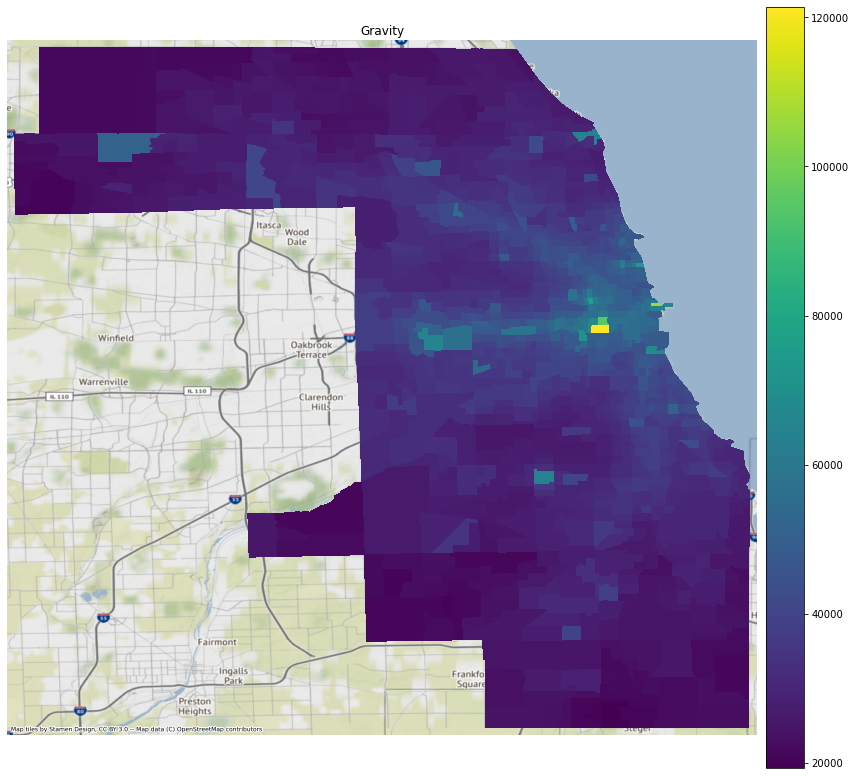

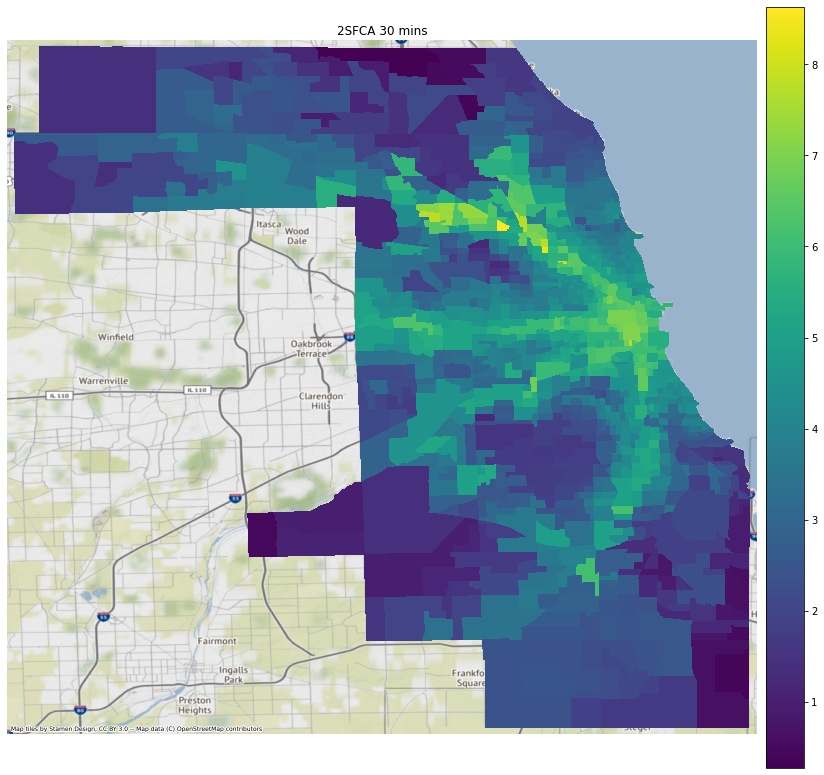

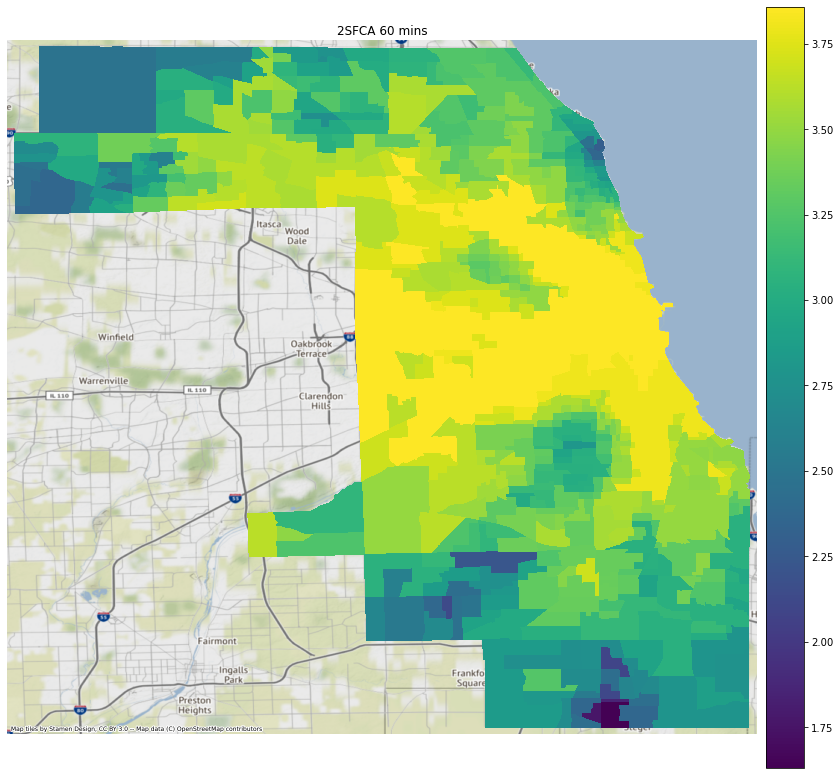

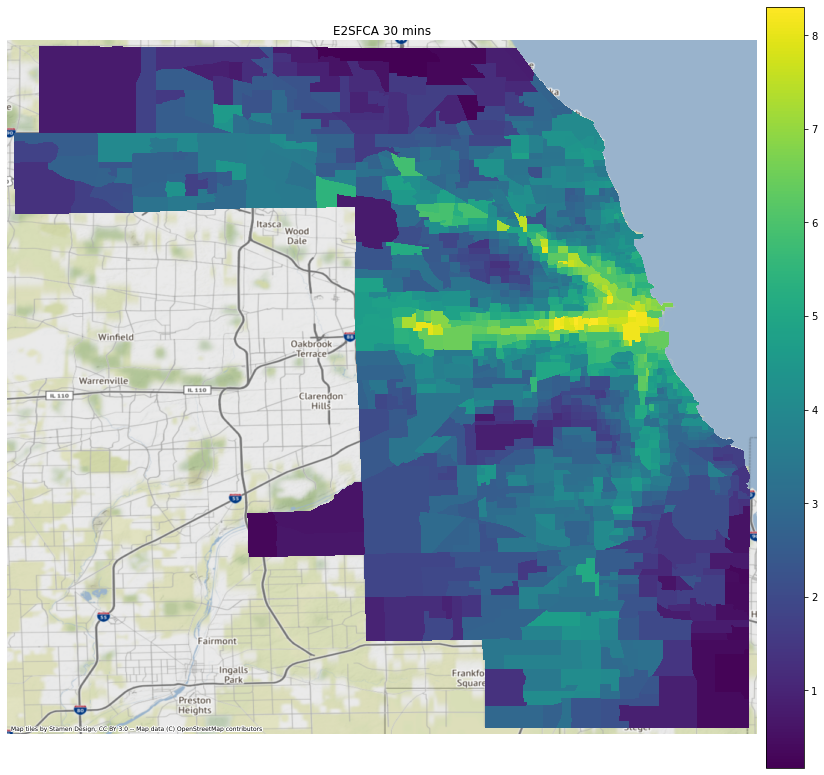

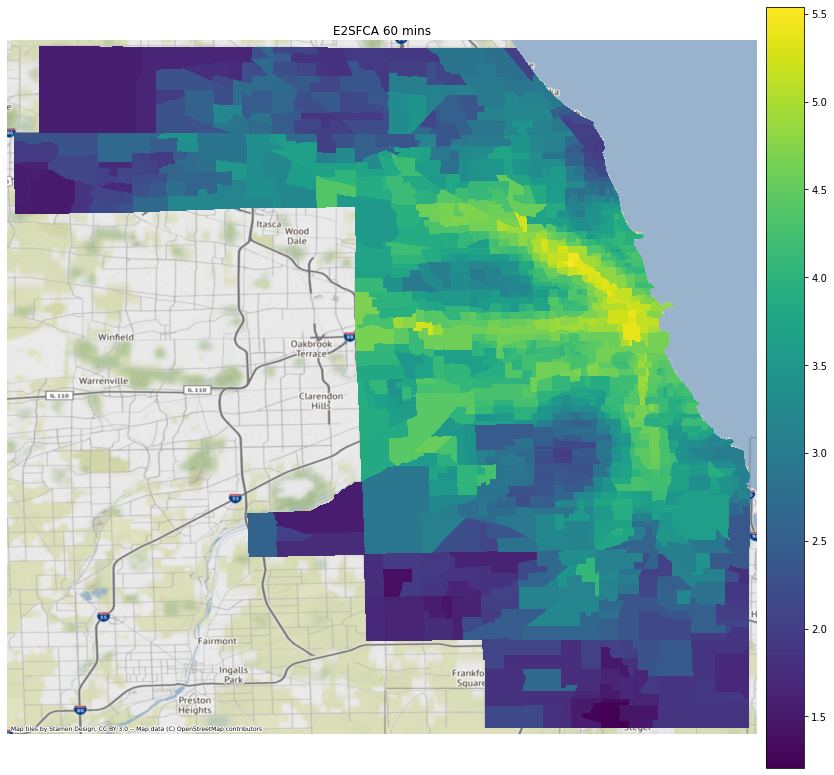

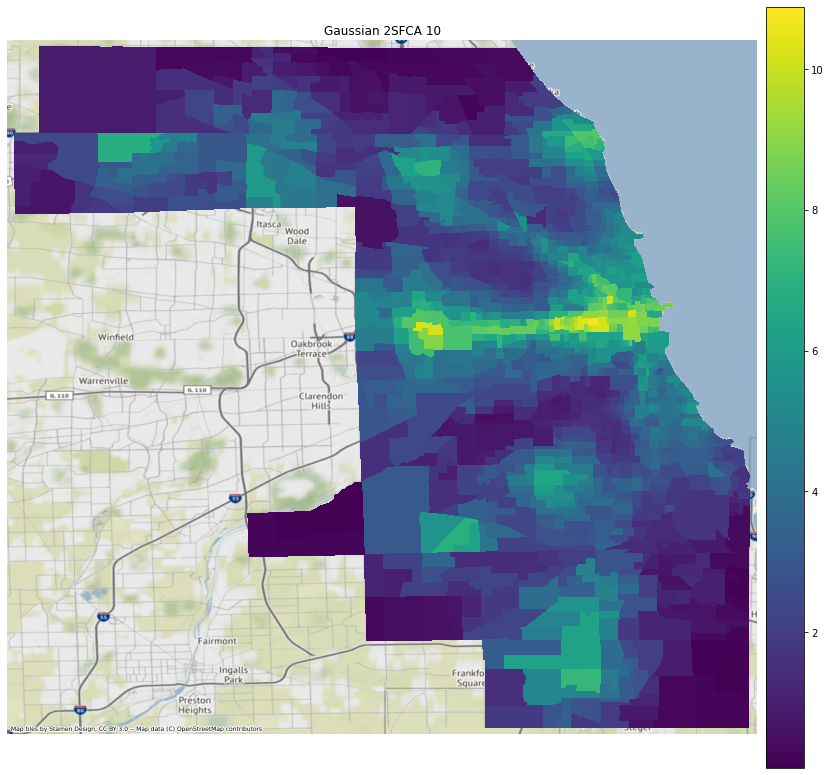

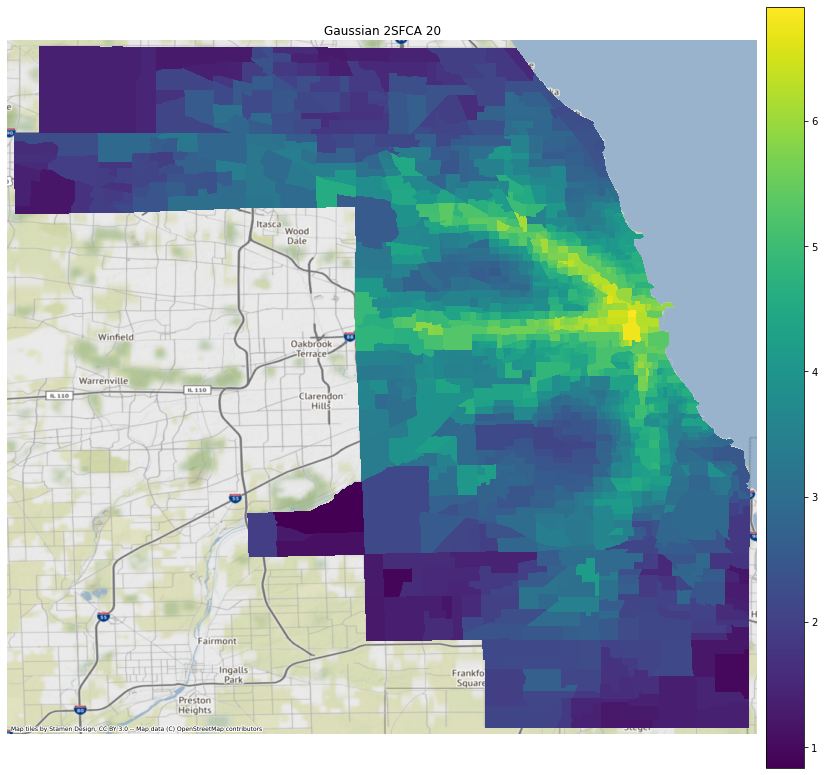

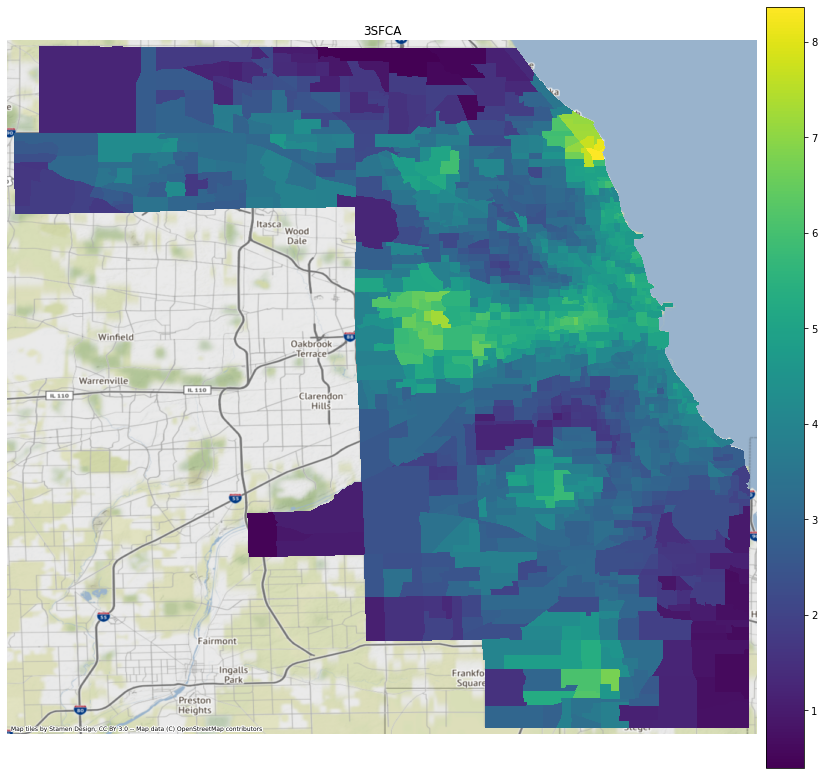

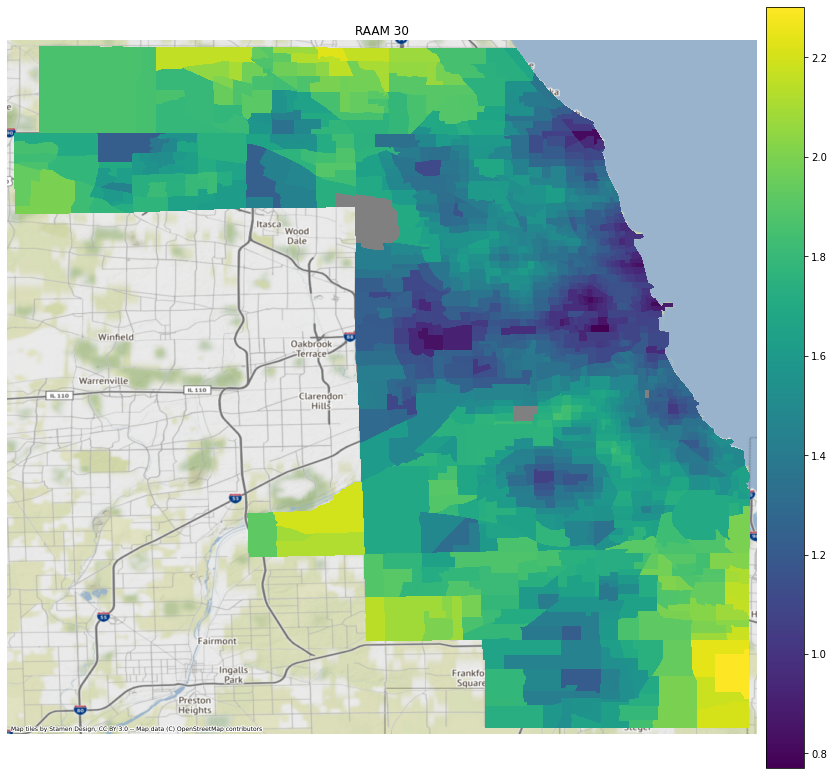

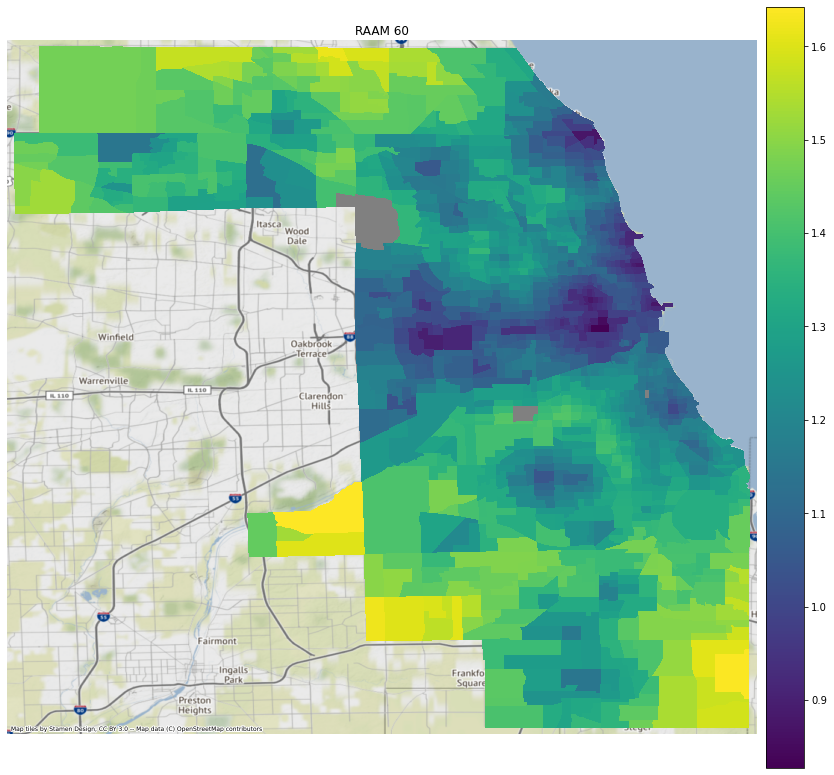

In [22]:
geom_result = gpd.GeoDataFrame(pop[[pop_id, "geometry"]].merge(result, on=pop_id))
geom_result = geom_result.set_crs(pop.crs)
for i, result_col in enumerate(result_cols):
    fig, ax = plt.subplots(figsize=figsize)
    ax = geom_result.plot(ax=ax, column=result_col, figsize=figsize, legend=True, antialiased=False,
                                missing_kwds= dict(color = "grey",), legend_kwds={'pad' : 0.01})
    ax.set_title(result_title_mapper[i])
    ax.margins(0.01)
    fig.subplots_adjust(hspace=0.0, wspace=0.0)
    ax.set_axis_off()
    cx.add_basemap(ax, attribution_size=6, crs=geom_result.crs.to_string())
geom_result.head()

In [23]:
corr = access_result.corr(method='kendall')
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
gravity_BEDS,1.000000,0.619946,0.678072,0.648095,0.740131,0.585684,0.797307,0.481011,-0.656957,-0.663228
2sfca_30_BEDS,0.619946,1.000000,0.617829,0.660640,0.702800,0.428490,0.763236,0.354754,-0.403097,-0.409948
2sfca_60_BEDS,0.678072,0.617829,1.000000,0.538545,0.791337,0.414585,0.748613,0.341379,-0.450638,-0.468534
e2sfca_30_BEDS,0.648095,0.660640,0.538545,1.000000,0.607776,0.708454,0.694587,0.646136,-0.594559,-0.589544
e2sfca_60_BEDS,0.740131,0.702800,0.791337,0.607776,1.000000,0.439592,0.869909,0.333908,-0.449454,-0.464655
g2sfca10_BEDS,0.585684,0.428490,0.414585,0.708454,0.439592,1.000000,0.517882,0.709587,-0.689235,-0.665462
g2sfca20_BEDS,0.797307,0.763236,0.748613,0.694587,0.869909,0.517882,1.000000,0.404641,-0.514542,-0.527022
3sfca_BEDS,0.481011,0.354754,0.341379,0.646136,0.333908,0.709587,0.404641,1.000000,-0.666412,-0.659424
raam30_BEDS,-0.656957,-0.403097,-0.450638,-0.594559,-0.449454,-0.689235,-0.514542,-0.666412,1.000000,0.898447
raam60_BEDS,-0.663228,-0.409948,-0.468534,-0.589544,-0.464655,-0.665462,-0.527022,-0.659424,0.898447,1.000000


In [24]:
access_result.to_file("../data/accessibility/CookHospitals.gpkg", driver="GPKG")